# Data Plotting
This notebook is used to plot the data from the dataset to visualize it.

## 1. Import Libraries and Load the Dataset

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dataset = pd.read_csv('steam_games.csv')

## 2. Data Visualization

### 2.1 Histograms
#### 2.1.1 Distribution of Game Prices

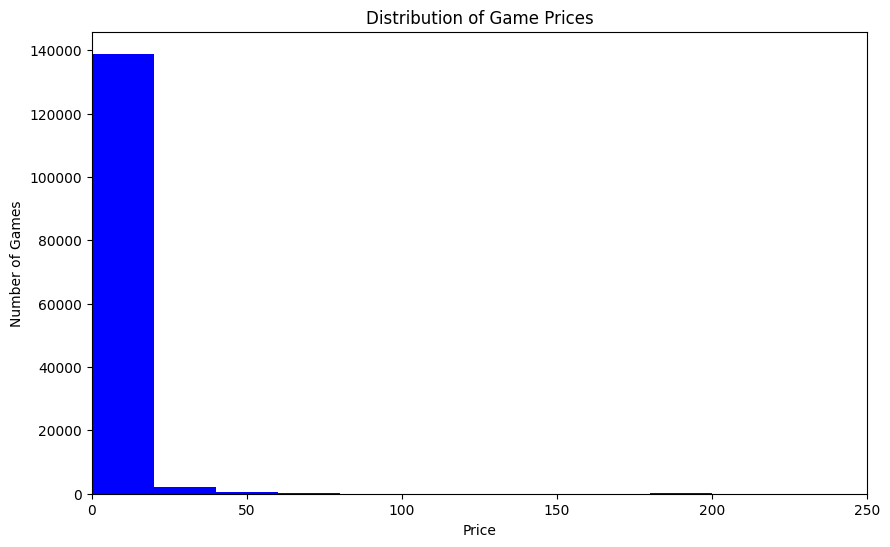

In [3]:
dataset['price'] = pd.to_numeric(dataset['price'], errors='coerce')
plt.figure(figsize=(10, 6))
plt.hist(dataset['price'].dropna(), bins=50, color='blue')
plt.title('Distribution of Game Prices')
plt.xlabel('Price')
plt.ylabel('Number of Games')
plt.xlim(0, 250)
plt.show()

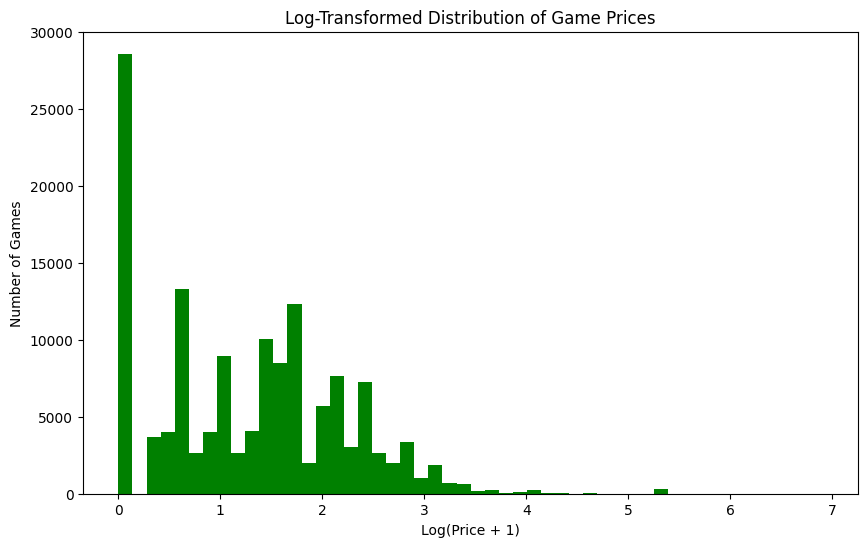

In [4]:
logplot_data = dataset[['price']].dropna().copy()

logplot_data['price'] = np.log1p(logplot_data['price'])

x = logplot_data['price'].to_numpy()

plt.figure(figsize=(10, 6))
plt.hist(x, bins=50, color='green')
plt.title('Log-Transformed Distribution of Game Prices')
plt.xlabel('Log(Price + 1)')
plt.ylabel('Number of Games')
plt.show()

### 2.1.2 Distribution of Release Years

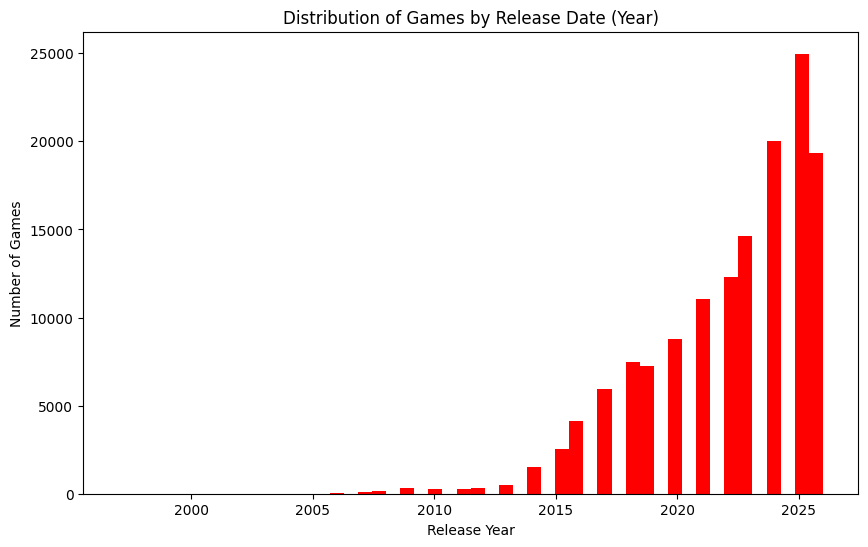

In [5]:
temp_dataset = dataset[['release_date']].dropna().copy()
temp_dataset['release_date'] = pd.to_datetime(temp_dataset['release_date'], errors='coerce')
temp_dataset['release_year'] = temp_dataset['release_date'].dt.year
plt.figure(figsize=(10, 6))
plt.hist(temp_dataset['release_year'].dropna(), bins=50, color='red')
plt.title('Distribution of Games by Release Date (Year)')
plt.xlabel('Release Year')
plt.ylabel('Number of Games')
plt.show()

## 2.2 Scatter Plots

### 2.2.1 Price vs Release Date

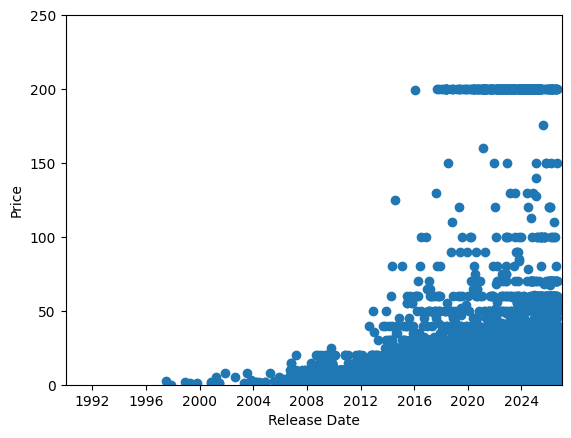

In [6]:
dataset['release_date'] = pd.to_datetime(dataset['release_date'], errors='coerce')
dataset['price'] = pd.to_numeric(dataset['price'], errors='coerce')
plot_data = dataset.dropna(subset=['release_date', 'price'])
plt.scatter(plot_data['release_date'], plot_data['price'])
plt.xlabel('Release Date')
plt.ylabel('Price')
plt.ylim(0, 250)
plt.xlim(pd.to_datetime('1990-01-01'), pd.to_datetime('2027-01-01'))
plt.show()

### 2.2.2 Price vs Positive Reviews

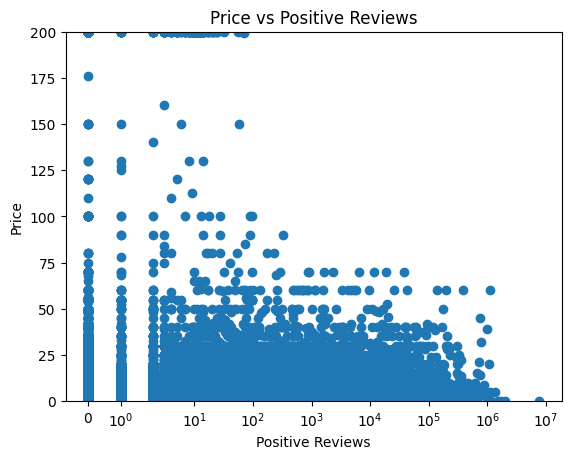

In [7]:
plt.scatter(plot_data['positive'], plot_data['price'])

plt.xscale('symlog')
plt.title('Price vs Positive Reviews')
plt.xlabel('Positive Reviews')
plt.ylabel('Price')
plt.ylim(0, 200)

plt.show()

### 2.2.3 Average Playtime vs Recommendations

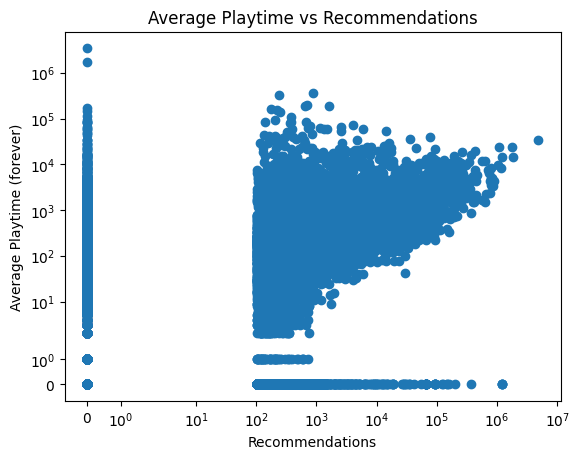

In [8]:
plt.scatter(plot_data['recommendations'], plot_data['average_playtime_forever'])

plt.xscale('symlog')
plt.yscale('symlog')
plt.title('Average Playtime vs Recommendations')
plt.xlabel('Recommendations')
plt.ylabel('Average Playtime (forever)')
plt.show()

### 2.2.4 Positive vs Negative Reviews (Symmetric Log Scale)

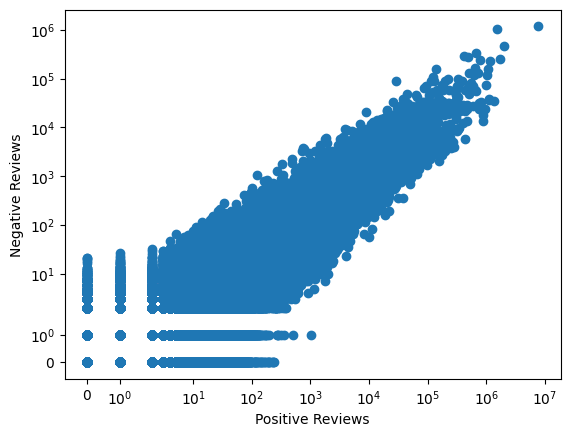

In [9]:
plt.scatter(plot_data['positive'], plot_data['negative'])

plt.xscale('symlog')
plt.yscale('symlog')
plt.xlabel('Positive Reviews')
plt.ylabel('Negative Reviews')

plt.show()